In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

In [8]:
phishing = fetch_ucirepo(id=327)

X = phishing.data.features.copy()
y = phishing.data.targets.iloc[:, 0].copy()

print("Dataset shape:", X.shape)
print("Number of instances:", X.shape[0])
print("Number of features:", X.shape[1])

display(X.head())

Dataset shape: (11055, 30)
Number of instances: 11055
Number of features: 30


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [11]:
df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
print("\\nFeature information:")
X.info()

Dataset shape: (11055, 31)
\nFeature information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   having_ip_address           11055 non-null  int64
 1   url_length                  11055 non-null  int64
 2   shortining_service          11055 non-null  int64
 3   having_at_symbol            11055 non-null  int64
 4   double_slash_redirecting    11055 non-null  int64
 5   prefix_suffix               11055 non-null  int64
 6   having_sub_domain           11055 non-null  int64
 7   sslfinal_state              11055 non-null  int64
 8   domain_registration_length  11055 non-null  int64
 9   favicon                     11055 non-null  int64
 10  port                        11055 non-null  int64
 11  https_token                 11055 non-null  int64
 12  request_url                 11055 non-null  int64
 13  url_of_anch

In [13]:
print("\\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

\nMissing values in each column:


,Missing Values
having_ip_address,0
url_length,0
shortining_service,0
having_at_symbol,0
double_slash_redirecting,0
prefix_suffix,0
having_sub_domain,0
sslfinal_state,0
domain_registration_length,0
favicon,0


In [15]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 5206


In [17]:
print("\\nSummary statistics:")
display(X.describe().T)

\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
having_ip_address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
url_length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
shortining_service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_at_symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
prefix_suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_sub_domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
sslfinal_state,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
domain_registration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0
favicon,11055.0,0.628584,0.777777,-1.0,1.0,1.0,1.0,1.0


\nTarget class distribution:


,Count
result,
-1,4898
1,6157


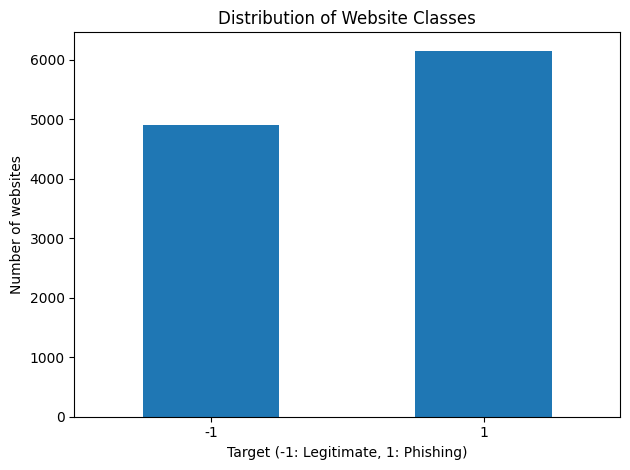

In [18]:
print("\\nTarget class distribution:")
display(y.value_counts().sort_index().to_frame("Count"))

y.value_counts().sort_index().plot(
    kind="bar",
    rot=0,
    title="Distribution of Website Classes",
    xlabel="Target (-1: Legitimate, 1: Phishing)",
    ylabel="Number of websites"
)
plt.tight_layout()
plt.show()

In [34]:

# Step 1: Count duplicate records
duplicate_count = df.duplicated().sum()

print("Original dataset size:", len(df))
print("Number of duplicate records:", duplicate_count)

# Step 2: Remove duplicate records
data = df.drop_duplicates().copy()

print("Dataset size after removing duplicates:", len(data))
print("Total records removed:", len(df) - len(data))

# Step 3: Separate features and target
X = data.drop("target", axis=1)
y = data["target"]

# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Step 5: Display class distribution
print("\nTraining class distribution:")
display(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

print("Testing class distribution:")
display(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)


Original dataset size: 11055
Number of duplicate records: 5206
Dataset size after removing duplicates: 5849
Total records removed: 5206

Training data shape: (4679, 30)
Testing data shape: (1170, 30)

Training class distribution:


,Percentage
target,
-1,51.61
1,48.39


Testing class distribution:


,Percentage
target,
-1,51.62
1,48.38


In [26]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": Pipeline([
        ("model", GaussianNB())
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

print("All five classification models are ready.")

All five classification models are ready.


In [27]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "training completed.")

Logistic Regression training completed.
Decision Tree training completed.
K-Nearest Neighbors training completed.
Naive Bayes training completed.


c:\Users\81161537\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine training completed.


In [28]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    # Probability of the phishing class (label 1)
    positive_index = list(model.classes_).index(1)
    y_score = model.predict_proba(X_test)[:, positive_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9128,0.9738,0.9000,0.9223,0.9110,0.8258
1,Decision Tree,0.9171,0.9219,0.9180,0.9099,0.9139,0.8340
2,K-Nearest Neighbors,0.9205,0.9726,0.9246,0.9099,0.9172,0.8409
3,Naive Bayes,0.6547,0.9635,0.9939,0.2880,0.4466,0.4122
4,Support Vector Machine,0.9402,0.9827,0.9247,0.9541,0.9391,0.8808


In [30]:
confusion_rows = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[-1, 1]
    ).ravel()

    confusion_rows.append({
        "Model": name,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp
    })

confusion_df = pd.DataFrame(confusion_rows)

display(confusion_df)

,Model,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,546,58,44,522
1,Decision Tree,558,46,51,515
2,K-Nearest Neighbors,562,42,51,515
3,Naive Bayes,603,1,403,163
4,Support Vector Machine,560,44,26,540


In [31]:
report_rows = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    report = classification_report(
        y_test,
        y_pred,
        labels=[-1, 1],
        target_names=["Legitimate", "Phishing"],
        output_dict=True,
        zero_division=0
    )

    for class_name in ["Legitimate", "Phishing"]:
        report_rows.append({
            "Model": name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": int(report[class_name]["support"])
        })

report_df = pd.DataFrame(report_rows)

display(report_df.round(3))

,Model,Class,Precision,Recall,F1-score,Support
0,Logistic Regression,Legitimate,0.925,0.904,0.915,604
1,Logistic Regression,Phishing,0.900,0.922,0.911,566
2,Decision Tree,Legitimate,0.916,0.924,0.920,604
3,Decision Tree,Phishing,0.918,0.910,0.914,566
4,K-Nearest Neighbors,Legitimate,0.917,0.930,0.924,604
5,K-Nearest Neighbors,Phishing,0.925,0.910,0.917,566
6,Naive Bayes,Legitimate,0.599,0.998,0.749,604
7,Naive Bayes,Phishing,0.994,0.288,0.447,566
8,Support Vector Machine,Legitimate,0.956,0.927,0.941,604
9,Support Vector Machine,Phishing,0.925,0.954,0.939,566


In [32]:
display(
    results_df.sort_values("F1 Score", ascending=False).reset_index(drop=True).round(4)
)

best_model = results_df.sort_values(
    ["F1 Score", "MCC"], ascending=False
).iloc[0]

print("Best model based on F1-score (MCC used as tie-breaker):", best_model["Model"])

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Support Vector Machine,0.9402,0.9827,0.9247,0.9541,0.9391,0.8808
1,K-Nearest Neighbors,0.9205,0.9726,0.9246,0.9099,0.9172,0.8409
2,Decision Tree,0.9171,0.9219,0.9180,0.9099,0.9139,0.8340
3,Logistic Regression,0.9128,0.9738,0.9000,0.9223,0.9110,0.8258
4,Naive Bayes,0.6547,0.9635,0.9939,0.2880,0.4466,0.4122


Best model based on F1-score (MCC used as tie-breaker): Support Vector Machine


In [33]:
model_dir = Path("model")
model_dir.mkdir(exist_ok=True)

model_files = {
    "logistic_regression": "Logistic Regression",
    "decision_tree": "Decision Tree",
    "knn": "K-Nearest Neighbors",
    "naive_bayes": "Naive Bayes",
    "svm": "Support Vector Machine"
}

for file_name, model_name in model_files.items():
    joblib.dump(models[model_name], model_dir / f"{file_name}.joblib")

# Save test data with target column
test_data = X_test.copy()
test_data["target"] = y_test
test_data.to_csv("test_data.csv", index=False)

# Save model comparison table
results_df.to_csv("model_comparison.csv", index=False)

# Save feature names for the Streamlit app
metadata = {
    "features": X.columns.tolist(),
    "models": model_files
}
import json
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Models and test data saved successfully.")

Models and test data saved successfully.
